# Modeling and Evaluating 

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import lightgbm as lgb
from lightgbm import early_stopping, log_evaluation
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
import os, sys, gc, time, warnings, pickle, psutil, random, optuna
from sklearn.metrics import mean_squared_error
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Do có nhiều sự lựa chọn nên ở đây tụi em quyết định chọn LightGBM do có hiệu năng và cũng là model mạnh nhất hiện tại

Sau nhiều lần thử nghiệm với các model khác thì thấy LightGBM hiệu suất hơn hẳn

# Tối ưu trọng số bằng Bayesian optimization

  Để tối ưu trọng số, nhóm đã sử dụng tối ưu trọng số bằng thuật toán Tree-structured Parzen Estimator thuộc phương pháp bayesian optimization.


### 📌 TPE là gì?

TPE (Tree-structured Parzen Estimator) là một thuật toán tối ưu hóa Bayes, dùng để chọn ra các siêu tham số tốt nhất bằng cách mô hình hóa xác suất của tham số dựa trên kết quả trước đó. Thay vì tìm giá trị nào tối ưu hóa hàm mất mát, TPE ước lượng phân phối xác suất và lấy mẫu thông minh từ đó để tìm ra tổ hợp tốt hơn qua từng vòng lặp.

---

### 🔍 Nguyên lý hoạt động

TPE không xây dựng mô hình trực tiếp cho `objective function`, mà nó **mô hình hóa xác suất ngược**:

$$[
P(x | y) \quad \text{thay vì} \quad P(y | x)
]$$

TPE chia kết quả các trial thành hai nhóm:
- **Good trials**: Những bộ tham số có điểm số tốt nhất (ví dụ, loss thấp nhất).
- **Bad trials**: Phần còn lại.

Sau đó, TPE:
- Ước lượng hai phân phối xác suất: $$( l(x) )$$ và $$( g(x) )$$
  - $$( l(x) = P(x | y < y^*) )$$
  - $$( g(x) = P(x | y \geq y^*) )$$
- Chọn tham số mới $$( x )$$ sao cho **tỉ lệ** $$( \frac{l(x)}{g(x)} )$$ là **cao nhất**.

---

### 📈 Ưu điểm

- Khả năng học từ lịch sử trial để cải thiện dần dần.
- Tốt hơn random search đặc biệt trong không gian tham số liên tục hoặc rộng.
- Hỗ trợ các loại siêu tham số: `int`, `float`, `categorical`, `log-uniform`, v.v.

---


In [2]:
df = pd.read_parquet('../../data/train_val.parquet')
print(df.head())

def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

df = downcast(df)
print(df.columns)


                   id  item_id  store_id  state_id  dept_id  cat_id     d  \
0  HOBBIES_1_001_CA_1     1438         1         1        4       2  1029   
1  HOBBIES_1_002_CA_1     1439         1         1        4       2  1029   
2  HOBBIES_1_003_CA_1     1440         1         1        4       2  1029   
3  HOBBIES_1_004_CA_1     1441         1         1        4       2  1029   
4  HOBBIES_1_005_CA_1     1442         1         1        4       2  1029   

   demand  lag_t7  rolling_mean_lag7_w7  ...  event_name_2  snap_CA  snap_TX  \
0     0.0     0.0              1.000000  ...             1        0        0   
1     0.0     1.0              0.142857  ...             1        0        0   
2     0.0     0.0              0.000000  ...             1        0        0   
3     3.0     0.0              1.142857  ...             1        0        0   
4     1.0     1.0              0.428571  ...             1        0        0   

   snap_WI sell_price  disaster_type  disaster_severity_

In [3]:
null_columns = df.columns[df.isna().any()].tolist()

# Kiểm tra giá trị 0
zero_columns = df.columns[(df == 0).any()].tolist()

print("Các cột có giá trị null:", null_columns)
print("Các cột có giá trị 0:", zero_columns)

Các cột có giá trị null: ['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28', 'sell_price', 'disaster_type']
Các cột có giá trị 0: ['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28', 'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'snap_CA', 'snap_TX', 'snap_WI', 'disaster_severity_flag', 'flag_ufc', 'gold_price']


In [6]:
df = df.drop(['date','disaster_type'],axis=1)
sample_submission = pd.read_csv('../../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):

    x = list(set(df.columns) - {'id', 'd', 'demand'}) # exclude 'date' from features
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)

    # return validation data for Optuna
    return train, valid, test, x, xvalid, yvalid



def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x, X_valid, y_valid = prep_train(df, 1000 - 28)

del df
gc.collect()

['snap_CA', 'flag_ufc', 'store_id', 'cat_id', 'state_id', 'humidity', 'event_name_2', 'month', 'rolling_mean_lag7_w7', 'lag_t7', 'rolling_mean_lag28_w7', 'wday', 'snap_TX', 'gold_price', 'item_id', 'rolling_mean_lag7_w28', 'snap_WI', 'lag_t28', 'sell_price', 'disaster_severity_flag', 'year', 'dept_id', 'event_name_1', 'rolling_mean_lag28_w28']


0

## Train model với optuna để tìm tham số tối ưu
Kết quả của việc tối ưu tham số ở đây được đánh giá dựa vào kết quả submit được ở cuộc thi, với score WRMSSE là 0.58231 thì nhóm đã lên đứng được ở Top64 cuộc thi

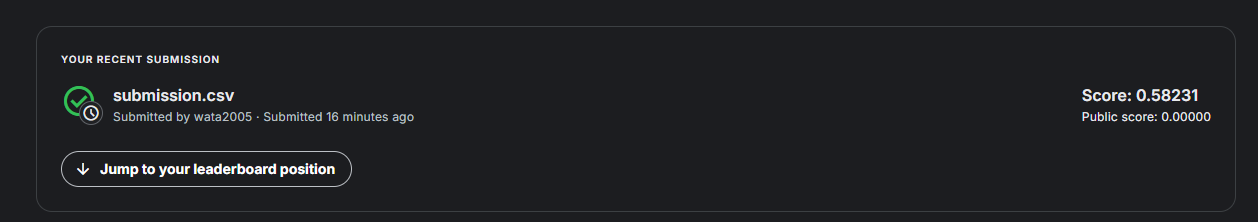
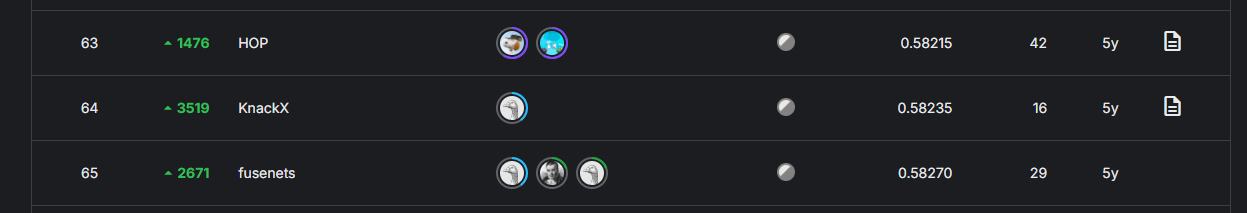

In [7]:
def objective(trial):
    # Gợi ý các hyperparameter
    param = {
        'objective': 'regression',
        'metric': 'rmse',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'feature_pre_filter': False,
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-8, 10.0, log=True),
        'learning_rate': trial.suggest_float('learning_rate', 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-8, 10.0, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 1000, 3000),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq': trial.suggest_int('bagging_freq', 1, 7),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    # Train
    gbm = lgb.train(
        param,
        train,
        valid_sets=[valid],
        num_boost_round=600,    
        callbacks=callbacks,
    )

    preds = gbm.predict(X_valid)
    rmse = np.sqrt(mean_squared_error(y_valid, preds))

    return rmse  # Tối ưu RMSE → minimize

# Study
study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=30)

# Kết quả
print("Best trial:")
trial = study.best_trial
print(f"  RMSE: {trial.value}")
print("  Params: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

[I 2025-05-05 12:13:24,287] A new study created in memory with name: no-name-2e6e1b01-b9d9-43d6-8402-07c222581405


Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 3.23305
[200]	valid_0's rmse: 2.91731
[300]	valid_0's rmse: 2.69125
[400]	valid_0's rmse: 2.53215
[500]	valid_0's rmse: 2.42193
[600]	valid_0's rmse: 2.34585
Did not meet early stopping. Best iteration is:
[600]	valid_0's rmse: 2.34585


[I 2025-05-05 12:26:53,440] Trial 0 finished with value: 2.345849494096966 and parameters: {'lambda_l1': 7.853467860640744, 'learning_rate': 0.002201361693215403, 'lambda_l2': 0.04411762059641074, 'num_leaves': 1298, 'feature_fraction': 0.7921866567075517, 'bagging_fraction': 0.9573450666671013, 'bagging_freq': 1, 'min_child_samples': 50}. Best is trial 0 with value: 2.345849494096966.


Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 4.12717
[200]	valid_0's rmse: 5.09017
Early stopping, best iteration is:
[3]	valid_0's rmse: 2.39358


[I 2025-05-05 12:30:38,583] Trial 1 finished with value: 2.3935829358655094 and parameters: {'lambda_l1': 0.26686304396088517, 'learning_rate': 1.4979449445564295, 'lambda_l2': 0.04466382206112637, 'num_leaves': 2017, 'feature_fraction': 0.6548155676291572, 'bagging_fraction': 0.7417977328296186, 'bagging_freq': 6, 'min_child_samples': 51}. Best is trial 0 with value: 2.345849494096966.


Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.18547
[200]	valid_0's rmse: 2.14195
[300]	valid_0's rmse: 2.12859
[400]	valid_0's rmse: 2.12154
[500]	valid_0's rmse: 2.11733
[600]	valid_0's rmse: 2.11606
Did not meet early stopping. Best iteration is:
[599]	valid_0's rmse: 2.11605


... (52 outputs left out)

[I 2025-05-05 18:25:04,174] Trial 28 finished with value: 2.132131331639772 and parameters: {'lambda_l1': 0.007595551444375121, 'learning_rate': 0.007056526266864699, 'lambda_l2': 0.12812725455824917, 'num_leaves': 2220, 'feature_fraction': 0.9458786915549822, 'bagging_fraction': 0.7994850517291395, 'bagging_freq': 4, 'min_child_samples': 11}. Best is trial 11 with value: 2.0673964744750775.


Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 3.40616
[200]	valid_0's rmse: 3.18753
[300]	valid_0's rmse: 3.00438
[400]	valid_0's rmse: 2.85196
[500]	valid_0's rmse: 2.72609
[600]	valid_0's rmse: 2.62254
Did not meet early stopping. Best iteration is:
[600]	valid_0's rmse: 2.62254


[I 2025-05-05 18:47:55,844] Trial 29 finished with value: 2.6225425127292517 and parameters: {'lambda_l1': 3.1286995366830315, 'learning_rate': 0.001234859195221899, 'lambda_l2': 0.05235545031660618, 'num_leaves': 2845, 'feature_fraction': 0.795315496997907, 'bagging_fraction': 0.9112700256600359, 'bagging_freq': 1, 'min_child_samples': 59}. Best is trial 11 with value: 2.0673964744750775.


Best trial:
  RMSE: 2.0673964744750775
  Params: 
    lambda_l1: 0.03868486588558565
    learning_rate: 0.047586309425667044
    lambda_l2: 8.320083593072901
    num_leaves: 2821
    feature_fraction: 0.9657558945465752
    bagging_fraction: 0.7792310380094438
    bagging_freq: 1
    min_child_samples: 7
